# 02 – Ortam, ajan ve eğitim: kod üzerinden

Bu notebook, `RL_Konu_Anlatimi.pdf`'in **6. ve 7. bölümünü** kod üzerinden gösterir.
Her hücre bir kavramı ele alır: önce PDF'teki karşılığı, sonra kod, sonra çıktıyı nasıl okuyacağın.

| Bölüm | Kavram | Dosya |
|---|---|---|
| A | Veri (karanlık + referans çiftleri) | `src/data.py` |
| B | Durum | `src/env.py` → `ozellikler`, `durum_no` |
| C | Eylemler | `src/env.py` → `eylem_uygula` |
| D | Ödül | `src/env.py` → `GoruntuOrtami.step` |
| E | Ortam: bir bölümü elle oyna | `src/env.py` → `GoruntuOrtami` |
| F | Ajan: Q-learning güncellemesi | `src/agents.py` |
| G | Eğitim | `train.py` ile aynı döngü |
| H | Eğitilmiş ajan + karşılaştırma | `evaluate.py` ile aynı mantık |

Hücreleri **sırayla** çalıştır (Shift + Enter).

In [16]:
import sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '..')                 # src/ klasörünü bulabilmek için (notebook notebooks/ içinde)
from src.data import lol_yukle
from src.env import (ozellikler, durum_no, eylem_uygula, EYLEM_ADLARI, DUR,
                     PARLAKLIK_SINIRLARI, KONTRAST_SINIRLARI, GURULTU_SINIRLARI,
                     ssim, psnr, GoruntuOrtami)
from src.agents import QLearning
from src.baselines import sabit_gamma_clahe
VERI = '../data/LOL'
print('Eylemler:', EYLEM_ADLARI)

Eylemler: ['aydinlat', 'karart', 'clahe', 'gurultu_azalt', 'keskinlestir', 'dur']


## A · Veri: karanlık görüntü + aydınlık referans

`lol_yukle` her görüntüyü 128×128'e küçültür ve 0–1 arası sayılara çevirir. Sonuç bir **çift listesi**: `[(karanlik, referans), ...]`.
Burada `gurultu_orani=0` diyerek yapay gürültü eklemiyoruz, PDF'teki örnekle aynı olsun diye.

15 test çifti · ilk dosya: 1.png
şekil: (128, 128, 3) · değer aralığı: 0.0 – 0.4


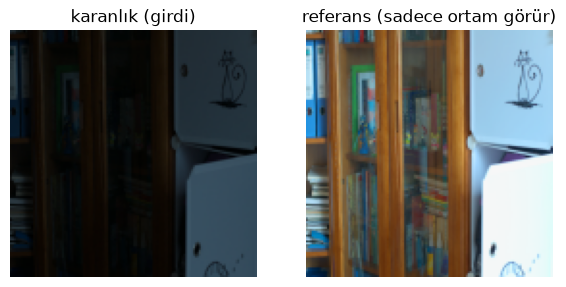

In [31]:
test, adlar = lol_yukle(VERI, 'eval15', boyut=128, gurultu_orani=0)
print(len(test), 'test çifti ·', 'ilk dosya:', adlar[0])
dusuk, ref = test[0]                      # eval15/1.png
print('şekil:', dusuk.shape, '· değer aralığı:', dusuk.min().round(3), '–', dusuk.max().round(3))

fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
ax[0].imshow(dusuk); ax[0].set_title('karanlık (girdi)')
ax[1].imshow(ref);   ax[1].set_title('referans (sadece ortam görür)')
for a in ax: a.axis('off')
plt.show()

**Dikkat:** `dusuk.shape` = (128, 128, 3) → 49.152 sayı. Q-tablosu bu kadar büyük bir şeyle çalışamaz. Bu yüzden B'de onu tek bir numaraya indireceğiz.

## B · Durum: görüntü → 3 sayı → tek numara (PDF 6. bölüm, "Durum")

**Adım 1:** `ozellikler(img)` üç sayı döndürür: parlaklık, kontrast, gürültü.

In [18]:
p, k, g = ozellikler(dusuk)
print(f'parlaklık = {p:.3f}   (gri piksellerin ortalaması)')
print(f'kontrast  = {k:.3f}   (gri piksellerin standart sapması)')
print(f'gürültü   = {g:.3f}   (görüntü − medyan filtreli hâli, parlaklığa bölünmüş)')

parlaklık = 0.097   (gri piksellerin ortalaması)
kontrast  = 0.090   (gri piksellerin standart sapması)
gürültü   = 0.035   (görüntü − medyan filtreli hâli, parlaklığa bölünmüş)


**Adım 2:** Her sayı sınırlara göre bir aralık numarasına çevrilir. `np.digitize(değer, sınırlar)` = "değer kaç sınırı geçti?" 

In [19]:
print('parlaklık sınırları:', PARLAKLIK_SINIRLARI, '→ 5 aralık (0–4)')
print('kontrast sınırları :', KONTRAST_SINIRLARI, '→ 4 aralık (0–3)')
print('gürültü sınırları  :', GURULTU_SINIRLARI, '→ 3 aralık (0–2)')
i = int(np.digitize(p, PARLAKLIK_SINIRLARI))
j = int(np.digitize(k, KONTRAST_SINIRLARI))
m = int(np.digitize(g, GURULTU_SINIRLARI))
print(f'\ni = {i}   j = {j}   m = {m}')

parlaklık sınırları: [0.1, 0.2, 0.35, 0.5] → 5 aralık (0–4)
kontrast sınırları : [0.05, 0.1, 0.2] → 4 aralık (0–3)
gürültü sınırları  : [0.015, 0.035] → 3 aralık (0–2)

i = 0   j = 1   m = 1


**Adım 3:** Üç aralık numarası tek bir durum numarasına birleştirilir: `durum = (i · 4 + j) · 3 + m`

In [20]:
elle = (i * 4 + j) * 3 + m
print(f'elle hesap : ({i}·4 + {j})·3 + {m} = {elle}')
print(f'durum_no() : {durum_no(dusuk)}')      # aynı sonucu vermeli

elle hesap : (0·4 + 1)·3 + 1 = 4
durum_no() : 4


✏️ **Dene:** Parlaklık 0,25, kontrast 0,12, gürültü 0,01 olsaydı durum kaç olurdu? Önce kâğıtta hesapla, sonra aşağıdaki hücrede kontrol et.

In [34]:
def durum_hesapla(p, k, g):
    i = int(np.digitize(p, PARLAKLIK_SINIRLARI)); j = int(np.digitize(k, KONTRAST_SINIRLARI)); m = int(np.digitize(g, GURULTU_SINIRLARI))
    return (i * 4 + j) * 3 + m 
print(durum_hesapla(0.25, 0.12, 0.01))

30


## C · Eylemler: 6 düğme (PDF 6. bölüm, "Eylemler")

`eylem_uygula(img, a)` eylem numarasına (0–5) göre filtreyi uygular ve **yeni bir görüntü** döndürür. Aşağıda aynı karanlık görüntüye her eylemi bir kez uyguluyoruz.

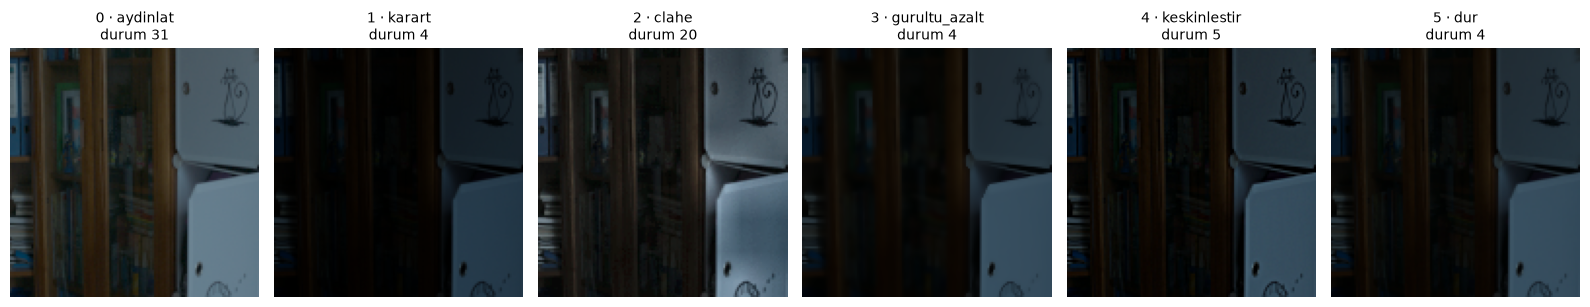

In [22]:
fig, ax = plt.subplots(1, 6, figsize=(16, 3.2))
for a in range(6):
    sonuc = eylem_uygula(dusuk, a)
    ax[a].imshow(np.clip(sonuc, 0, 1)); ax[a].axis('off')
    ax[a].set_title(f'{a} · {EYLEM_ADLARI[a]}\ndurum {durum_no(sonuc)}', fontsize=10)
plt.tight_layout(); plt.show()

**Okuma:** Başlıktaki "durum" sayısı, eylemden **sonra** görüntünün düştüğü oda. Aydınlatınca durum 4'ten başka bir numaraya geçiyor: parlaklık aralığı değişti. `dur` (5) görüntüyü değiştirmez.

## D · Ödül: SSIM ne kadar arttı? (PDF 6. bölüm, "Ödül")

`r = 10 · (SSIM_sonra − SSIM_önce) − 0,01` · "dur" eyleminin ödülü 0.
Aşağıda her eylemi **ilk adım** olarak deneyip ödülü elle hesaplıyoruz. PDF'teki tabloyla aynı sayılar çıkmalı (durum 4, başlangıç SSIM 0,209).

başlangıç SSIM = 0.209

eylem           SSIM sonra     ödül
aydinlat             0.597    +3.87
karart               0.116    -0.94
clahe                0.415    +2.05
gurultu_azalt        0.193    -0.16
keskinlestir         0.226    +0.16
dur                  0.209    +0.00


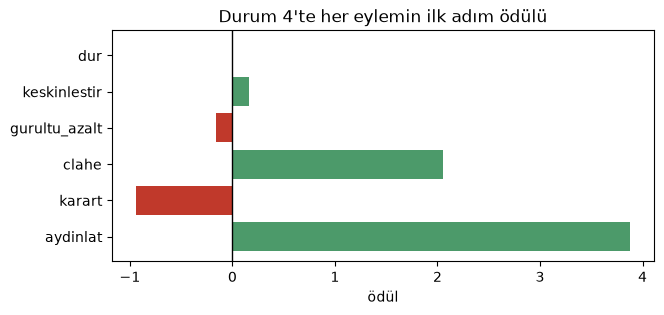

In [23]:
ssim_once = ssim(dusuk, ref)
print(f'başlangıç SSIM = {ssim_once:.3f}\n')
print(f'{"eylem":15s} {"SSIM sonra":>10s} {"ödül":>8s}')
oduller = []
for a in range(6):
    if a == DUR:
        r = 0.0; s_sonra = ssim_once
    else:
        s_sonra = ssim(eylem_uygula(dusuk, a), ref)
        r = 10 * (s_sonra - ssim_once) - 0.01
    oduller.append(r)
    print(f'{EYLEM_ADLARI[a]:15s} {s_sonra:10.3f} {r:+8.2f}')

plt.figure(figsize=(7, 3))
plt.barh(EYLEM_ADLARI, oduller, color=['#4c9a6a' if r > 0 else '#c0392b' for r in oduller])
plt.axvline(0, color='k', lw=1); plt.xlabel('ödül'); plt.title('Durum 4\'te her eylemin ilk adım ödülü'); plt.show()

## E · Ortam: bir bölümü elle oyna

Ortam iki fonksiyonla kullanılır:
- `env.reset(idx)` → bir görüntü seçer, **durum** döndürür.
- `env.step(a)` → eylemi uygular, **(yeni_durum, ödül, bitti)** döndürür.

Aşağıda ajan yok: düğmeleri **biz** seçiyoruz. Listeyi değiştirip tekrar çalıştırabilirsin.

In [24]:
env = GoruntuOrtami(test)
s = env.reset(idx=0)
print('başlangıç durumu:', s, '· SSIM', round(env.skor, 3))
benim_secimlerim = [0, 4, 0, 5]          # aydınlat, keskinleştir, aydınlat, dur
for a in benim_secimlerim:
    s2, r, bitti = env.step(a)
    print(f'{EYLEM_ADLARI[a]:14s} → yeni durum {s2:2d} · ödül {r:+.2f} · SSIM {env.skor:.3f} · bitti={bitti}')
    if bitti: break
print('\ngeçmiş:', env.gecmis)

başlangıç durumu: 4 · SSIM 0.209
aydinlat       → yeni durum 31 · ödül +3.87 · SSIM 0.597 · bitti=False
keskinlestir   → yeni durum 32 · ödül +0.44 · SSIM 0.642 · bitti=False
aydinlat       → yeni durum 44 · ödül +2.29 · SSIM 0.872 · bitti=False
dur            → yeni durum 44 · ödül +0.00 · SSIM 0.872 · bitti=True

geçmiş: ['aydinlat', 'keskinlestir', 'aydinlat', 'dur']


**Okuma:** `bitti=True` ya "dur" seçilince ya da 5. adımda gelir. Bir bölüm = `reset` ile başlayıp `bitti=True` olana kadar süren adımlar.

## F · Ajan: Q-learning güncellemesi adım adım

`src/agents.py` → `QLearning.bolum_oyna` şu iki satırla öğrenir:
```python
hedef = r if bitti else r + self.gama * self.Q[s2].max()
self.Q[s, a] += self.alfa * (hedef - self.Q[s, a])
```
Aşağıdaki hücre aynı döngüyü **yazdırarak** çalıştırır: her adımda eski Q, hedef, hata ve yeni Q'yu görürsün. Bu, PDF'teki formülün (ve sohbetteki örneğin) kodda bire bir karşılığı.

In [25]:
ajan = QLearning(env.durum_sayisi, env.eylem_sayisi, alfa=0.1, gama=0.95, epsilon=1.0, seed=0)
print('Q-tablosu boyutu:', ajan.Q.shape, '· hepsi 0 mı?', (ajan.Q == 0).all())

s, bitti, adim = env.reset(idx=0), False, 0
while not bitti:
    adim += 1
    a = ajan.eylem_sec(s)                                   # ε = 1 → rastgele (keşif)
    s2, r, bitti = env.step(a)
    eski = ajan.Q[s, a]
    gelecek = 0 if bitti else ajan.Q[s2].max()
    hedef = r if bitti else r + ajan.gama * gelecek
    hata = hedef - eski
    ajan.Q[s, a] = eski + ajan.alfa * hata
    print(f'adım {adim}: s={s:2d} a={EYLEM_ADLARI[a]:13s} r={r:+.2f} s2={s2:2d}')
    if bitti:
        print(f'        bitti → gelecek yok · hedef = r = {hedef:+.3f}')
    else:
        print(f'        hedef = r + γ·max Q(s2) = {r:+.3f} + 0,95·({gelecek:+.3f}) = {hedef:+.3f}')
    print(f'        hata  = hedef − eski Q = {hedef:+.3f} − ({eski:+.3f}) = {hata:+.3f}')
    print(f'        yeni Q = eski Q + α·hata = {eski:+.3f} + 0,1·({hata:+.3f}) = {ajan.Q[s, a]:+.4f}')
    s = s2

Q-tablosu boyutu: (60, 6) · hepsi 0 mı? True
adım 1: s= 4 a=gurultu_azalt r=-0.16 s2= 4
        hedef = r + γ·max Q(s2) = -0.162 + 0,95·(+0.000) = -0.162
        hata  = hedef − eski Q = -0.162 − (+0.000) = -0.162
        yeni Q = eski Q + α·hata = +0.000 + 0,1·(-0.162) = -0.0162
adım 2: s= 4 a=karart        r=-0.84 s2= 4
        hedef = r + γ·max Q(s2) = -0.838 + 0,95·(+0.000) = -0.838
        hata  = hedef − eski Q = -0.838 − (+0.000) = -0.838
        yeni Q = eski Q + α·hata = +0.000 + 0,1·(-0.838) = -0.0838
adım 3: s= 4 a=karart        r=-0.50 s2= 1
        hedef = r + γ·max Q(s2) = -0.504 + 0,95·(+0.000) = -0.504
        hata  = hedef − eski Q = -0.504 − (-0.084) = -0.421
        yeni Q = eski Q + α·hata = -0.084 + 0,1·(-0.421) = -0.1258
adım 4: s= 1 a=keskinlestir  r=+0.01 s2= 1
        hedef = r + γ·max Q(s2) = +0.011 + 0,95·(+0.000) = +0.011
        hata  = hedef − eski Q = +0.011 − (+0.000) = +0.011
        yeni Q = eski Q + α·hata = +0.000 + 0,1·(+0.011) = +0.0011
adım 5: s= 

**Okuma:** İlk bölümde tablo boş olduğu için `max Q(s′,·)` hep 0, eski Q hep 0. Hedef sadece ödülden oluşuyor. Bölümler ilerledikçe `gelecek` sütunu da dolmaya başlar: hedefin değeri geriye doğru yayılır.

Son adımda `bitti=True` olduğu için hedef = r (gelecek yok).

## G · Eğitim: aynı şeyi 3000 kez (PDF 7. bölüm)

`train.py` tam olarak bunu yapar: eğitim görüntülerinden rastgele seçip `bolum_oyna` çağırır. Her bölümden sonra ε biraz küçülür. ~30 saniye sürer.

son ε: 0.05 · ziyaret edilen durum sayısı: 48 / 60


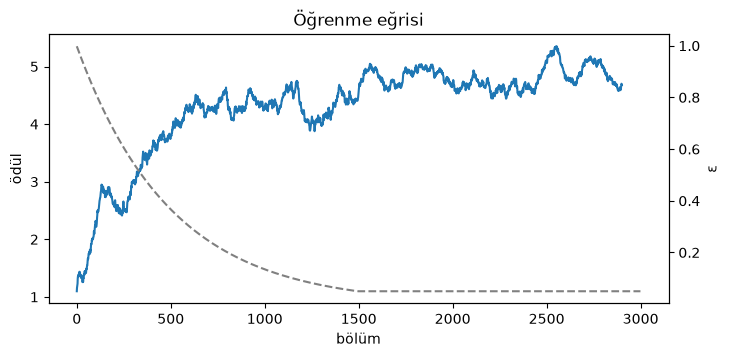

In [26]:
egitim, _ = lol_yukle(VERI, 'our485', boyut=128, seed=0)   # yarısına yapay gürültü ekli
env_e = GoruntuOrtami(egitim, seed=0)
ajan = QLearning(env_e.durum_sayisi, env_e.eylem_sayisi, seed=0)
toplam_oduller, epsilonlar = [], []
for b in range(3000):
    toplam_oduller.append(ajan.bolum_oyna(env_e))
    epsilonlar.append(ajan.epsilon)
print('son ε:', round(ajan.epsilon, 3), '· ziyaret edilen durum sayısı:', int((np.abs(ajan.Q).sum(1) > 0).sum()), '/ 60')

fig, ax1 = plt.subplots(figsize=(8, 3.5))
ax1.plot(np.convolve(toplam_oduller, np.ones(100) / 100, mode='valid'), label='toplam ödül (100 bölüm ort.)')
ax1.set_xlabel('bölüm'); ax1.set_ylabel('ödül')
ax2 = ax1.twinx(); ax2.plot(epsilonlar, color='gray', ls='--', label='ε'); ax2.set_ylabel('ε')
ax1.set_title('Öğrenme eğrisi'); plt.show()

**Okuma:** Ödül eğrisi yükseliyor, ε (kesikli) 1'den 0,05'e iniyor. Başta ajan rastgele oynadığı için ödül düşük; ε küçüldükçe öğrendiğini kullanıyor.

## H · Eğitilmiş ajanı izle ve karşılaştır

**1) Q-tablosundan bir satır:** Durum 4'teki 6 sayı. Politika = en büyüğü.

In [27]:
for ad, q in zip(EYLEM_ADLARI, ajan.Q[4]):
    print(f'Q[4, {ad:13s}] = {q:+.2f}')
print('politika: durum 4 →', EYLEM_ADLARI[int(np.argmax(ajan.Q[4]))])

Q[4, aydinlat     ] = +4.85
Q[4, karart       ] = +1.40
Q[4, clahe        ] = +0.45
Q[4, gurultu_azalt] = +1.75
Q[4, keskinlestir ] = +1.16
Q[4, dur          ] = +0.00
politika: durum 4 → aydinlat


**2) Aynı görüntüde keşifsiz (ε = 0) bir bölüm:** PDF'teki "eğitilmiş ajanın davranışı" tablosuyla aynı (ya da çok yakın) adımlar çıkmalı.

In [28]:
s, bitti = env.reset(idx=0), False
while not bitti:
    a = ajan.eylem_sec(s, ogrenme=False)                    # ogrenme=False → keşif yok
    q = ajan.Q[s, a]
    s2, r, bitti = env.step(a)
    print(f'durum {s:2d} → {EYLEM_ADLARI[a]:13s} (Q={q:+.2f}) · ödül {r:+.2f} · SSIM {env.skor:.3f}')
    s = s2

durum  4 → aydinlat      (Q=+4.85) · ödül +3.87 · SSIM 0.597
durum 31 → keskinlestir  (Q=+0.31) · ödül +0.44 · SSIM 0.642
durum 32 → aydinlat      (Q=+0.53) · ödül +2.29 · SSIM 0.872
durum 44 → gurultu_azalt (Q=+0.59) · ödül -0.04 · SSIM 0.870
durum 43 → dur           (Q=+0.00) · ödül +0.00 · SSIM 0.870


**3) Bütün test seti: ajan mı, sabit Gamma + CLAHE mi?**

In [29]:
def ajan_uygula(dusuk):
    img = dusuk
    for _ in range(5):
        a = ajan.eylem_sec(durum_no(img), ogrenme=False)
        if a == DUR: break
        img = eylem_uygula(img, a)
    return img

sa = [ssim(ajan_uygula(d), r) for d, r in test]
sg = [ssim(sabit_gamma_clahe(d, r)[0], r) for d, r in test]
print(f'Q-learning ajanı   ortalama SSIM = {np.mean(sa):.3f}')
print(f'Sabit Gamma+CLAHE  ortalama SSIM = {np.mean(sg):.3f}')
print('ajanın kazandığı görüntü sayısı:', sum(x > y for x, y in zip(sa, sg)), '/', len(test))

Q-learning ajanı   ortalama SSIM = 0.762
Sabit Gamma+CLAHE  ortalama SSIM = 0.707
ajanın kazandığı görüntü sayısı: 9 / 15


Not: Buradaki test görüntüleri gürültüsüz (A'da `gurultu_orani=0`). `evaluate.py` test görüntülerinin bir kısmına gürültü eklediği için sayılar PDF'teki tablodan biraz farklı çıkabilir.

## ✅ Kendini test et
1. B'de `durum_no` yerine görüntünün kendisini kullansaydık Q-tablosu nasıl olurdu?
2. F'deki çıktıda son adımda hedef neden sadece `r`?
3. G'de `range(3000)` yerine `range(300)` yaparsan H'deki sonuç ne olur? Dene.
4. H-1'deki Q[4] değerleri, D'deki ilk adım ödülleriyle aynı sırada mı? Neden tam aynı değiller?